<a href="https://colab.research.google.com/github/nishapandey9098/medical-image-classifier-compression/blob/main/Project3_Model_Compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Making a Medical Image Classifier Small and Fast
### Compressing a classifier for offline use: FP16, INT8 and pruning trade-offs

**Who this is for:** complete beginners. Run the cells in order (top to bottom) and read the short explanation above each one.

**The idea.** In a rural clinic the AI may have to run **offline** on a cheap phone or an old laptop: little memory, a slow processor, no internet. In Projects 1 and 2 your model was a normal 45 MB ResNet-18 that ran on a GPU. Here you shrink it and measure, honestly, what you gain and what you lose:

1. How much **smaller** does it get (megabytes)?
2. How much **faster** is it on a CPU (milliseconds per image)?
3. Does it get **less accurate**, and do its confidence scores get **less honest** (calibration, from Project 2)?

**You will try:** FP16 (half-precision numbers), INT8 (8-bit integers, "quantization"), two kinds of **pruning** (removing parts of the network), and a combination. Every variant is exported to the **ONNX** format and timed with **ONNX Runtime** on the CPU.

**You need:** Project 1 finished, in particular the two reference models saved by Project 1's Step 9: `models/reference_pneumoniamnist.pt` and `models/reference_retinamnist.pt` inside `ML_Project1_Ablation/full_64px` on your Google Drive.

**Time:** about 5 minutes for the quick test, about 15 to 20 minutes for the full run.

## Before you start (3 minutes)

1. **Check Google Drive.** Open `ML_Project1_Ablation`, then `full_64px`, then `models`. You should see `reference_pneumoniamnist.pt` and `reference_retinamnist.pt`. (They are created by Step 9 of the Project 1 notebook. If they are missing, run that notebook again with `QUICK_TEST = False`.)
2. Open this notebook in Colab (*File, Upload notebook*). Turn on the free GPU: **Runtime, Change runtime type, T4 GPU, Save.** The GPU is used only to fine-tune the pruned models. **All speed measurements run on the CPU**, on purpose.
3. Run each cell with **Shift + Enter**, from top to bottom. Wait for a cell to finish before running the next. Do not skip cells.
4. Start with `QUICK_TEST = True` (about 5 minutes), then switch to `False` for the real run, exactly like in Projects 1 and 2.
5. Handle the error text. A single compression method that fails is **skipped with a message** and the rest of the notebook continues.

## Nine ideas you need (read once, 5 minutes)

1. **Why compress?** Offline devices have limited memory, a slow CPU and a battery. A smaller and faster model can run where a big one cannot.
2. **Numbers and bits.** A normal model stores every weight as a 32-bit number (**FP32**). **FP16** uses 16 bits and **INT8** uses 8 bits, so the file becomes about 2x and 4x smaller.
3. **Quantization.** Storing and computing with fewer bits. We use **post-training static INT8 quantization**: no re-training, but we show the model a few hundred typical images (the **calibration** set, taken from the *training* data) so it can learn the usual range of values inside every layer.
4. **Pruning.** Removing parts of the network. **Unstructured pruning** sets the smallest individual weights to zero (the network keeps its shape but becomes *sparse*). **Structured pruning** removes whole *filters* (the network really becomes smaller). After pruning we **fine-tune** for a few epochs to recover accuracy, and we also show what happens *without* fine-tuning ("one-shot").
5. **ONNX and ONNX Runtime.** ONNX is a standard file format for trained models. ONNX Runtime is a fast engine that runs ONNX files on CPUs and phones.
6. **Benchmarking properly.** One timing means nothing. We (a) do untimed **warm-up** runs, (b) time many runs, (c) report the **median** and the spread (**IQR**) instead of the average, (d) use the **same input and the same number of threads** for every model, (e) **interleave** the models (in a different random order every round) so a slow moment of the computer does not unfairly hit one model, and (f) **report the hardware**. Compare *ratios* (speed-up), not absolute milliseconds.
7. **What we measure.** Size (MB, and size after zip compression), latency (ms per image), accuracy and the Project 1 main score (AUC or QWK), calibration (ECE, NLL from Project 2), and **agreement with the FP32 model** (how many predictions changed).
8. **Compression does not automatically mean speed.** A smaller file is not always faster. Zeros do not make a CPU faster unless it has special sparse kernels, and some CPUs run FP16 slowly. This is exactly what you will measure.
9. **Trade-offs, honestly.** There is no free lunch. We pick a variant using the **validation** set (never the test set) with a stated tolerance, and then report its test results. The test sets are small, so we put bootstrap confidence intervals on every change.

## Step 1: Set up

Cell 1a installs the libraries (about 1 minute). Cell 1b loads them. Cell 1c holds the **settings**. Cell 1d connects Google Drive (a pop-up asks for permission: click *Allow*) and records the computer you are measuring on.

In [40]:
# 1a. Install the libraries (ONNX tools, ONNX Runtime and MedMNIST). Takes about 1 minute.
!pip install -q onnx onnxruntime onnxconverter-common onnxscript medmnist

In [41]:
# 1b. Load the libraries we need.
import os, re, io, time, math, random, itertools, json, platform, shutil, copy, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import scipy
import sklearn
from scipy import stats
from scipy.stats import rankdata
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models
import onnxruntime as ort

import medmnist
from medmnist import INFO, PneumoniaMNIST, RetinaMNIST

try:
    import onnx
    ONNX_VERSION = onnx.__version__
except Exception:
    ONNX_VERSION = "not installed"

print("Libraries loaded. PyTorch", torch.__version__, "| ONNX Runtime", ort.__version__, "| ONNX", ONNX_VERSION)

Libraries loaded. PyTorch 2.14.1+cu130 | ONNX Runtime 1.32.0 | ONNX 1.23.2


In [42]:
# 1c. SETTINGS (you can change these)
QUICK_TEST = False        # True  = quick check (about 5 minutes, results are NOT meaningful).
                         # False = the REAL run (about 15 to 20 minutes). Switch only after the quick test works.
P1_DIR = "/content/drive/MyDrive/ML_Project1_Ablation/full_64px"   # the folder where Project 1 saved its results
IMG_SIZE = 64            # must be the same as in Project 1

N_THREADS = 1            # CPU threads used by ONNX Runtime. 1 = like a cheap device, and the numbers are more stable
UNSTRUCTURED_LEVELS = [0.5, 0.7, 0.9]    # share of weights set to zero
STRUCTURED_LEVELS = [0.25, 0.5, 0.75]    # share of filters removed inside every residual block
COMBO_LEVEL = 0.5                        # which structured level is also quantized to INT8
FT_EPOCHS = 8            # fine-tuning epochs after pruning
FT_LR = 2e-4             # fine-tuning learning rate
BATCH_SIZE = 64
WEIGHT_DECAY = 1e-4
CALIB_N = 128            # calibration images for INT8 (taken from the TRAINING set)
INT8_PER_CHANNEL = True  # one scale per filter (more accurate)
INT8_REDUCE_RANGE = False

BENCH_ROUNDS = 5         # speed test: how many rounds ...
BENCH_ITERS = 40         # ... of how many timed runs per model and round
BENCH_WARMUP = 20        # untimed warm-up runs per model
N_BINS = 15              # confidence bins for ECE
N_BOOT = 1000            # bootstrap repetitions
TOLERANCE = {"pneumoniamnist": 0.01, "retinamnist": 0.03}   # accepted DROP of the validation score (AUC / QWK) when picking a variant
EVAL_LIMIT = None        # None = use all validation and test images

if QUICK_TEST:
    FT_EPOCHS, CALIB_N, N_BOOT, EVAL_LIMIT = 1, 32, 100, 100
    BENCH_ROUNDS, BENCH_ITERS, BENCH_WARMUP = 2, 10, 5

RUN_NAME = "quick_test" if QUICK_TEST else "full"
USE_GPU = torch.cuda.is_available()
device = torch.device("cuda" if USE_GPU else "cpu")
print("Mode:", "QUICK TEST" if QUICK_TEST else "FULL RUN", "| fine-tuning device:", device, "|",
      str(torch.cuda.get_device_name(0)) if USE_GPU else "NO GPU FOUND (fine-tuning will be slow)")

Mode: FULL RUN | fine-tuning device: cuda | Tesla T4


In [43]:
# 1d. Where to save results, and which computer we are measuring on.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/ML_Project3_Compression"
    ONNX_ROOT = "/content/onnx_models"            # the big model files stay on the fast local disk
except Exception as e:
    print("Google Drive not used (" + type(e).__name__ + "). Saving in a local folder instead.")
    BASE_DIR = "./ML_Project3_Compression"
    ONNX_ROOT = "./onnx_models"

OUT_DIR = os.path.join(BASE_DIR, RUN_NAME)
ONNX_DIR = os.path.join(ONNX_ROOT, RUN_NAME)
for d_ in [OUT_DIR, os.path.join(OUT_DIR, "figures"), os.path.join(OUT_DIR, "recommended_models"), ONNX_DIR]:
    os.makedirs(d_, exist_ok=True)
print("Results will be saved in:", OUT_DIR)

def cpu_info():
    """Name and useful features of the CPU (the speed test only means something together with this)."""
    model, keep = platform.processor() or "unknown", []
    try:
        with open("/proc/cpuinfo") as f:
            txt = f.read()
        m = re.search(r"model name\s*:\s*(.+)", txt)
        model = m.group(1).strip() if m else model
        fl = re.search(r"flags\s*:\s*(.+)", txt)
        flags = fl.group(1).split() if fl else []
        keep = [x for x in ["avx2", "avx512f", "avx512_vnni", "avx_vnni", "amx_int8", "amx_bf16"] if x in flags]
    except Exception:
        pass
    return {"cpu_model": model, "cpu_cores_visible": os.cpu_count(), "cpu_features": keep}

env = {
    "python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
    "onnxruntime": ort.__version__, "onnx": ONNX_VERSION, "numpy": np.__version__, "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "opencv": cv2.__version__,
    "medmnist": getattr(medmnist, "__version__", "unknown"),
    "fine_tuning_gpu": str(torch.cuda.get_device_name(0)) if USE_GPU else "none",
    **cpu_info(),
    "speed_test": {"threads": N_THREADS, "rounds": BENCH_ROUNDS, "iters_per_round": BENCH_ITERS, "warmup": BENCH_WARMUP, "batch_size": 1},
    "img_size": IMG_SIZE, "unstructured_levels": UNSTRUCTURED_LEVELS, "structured_levels": STRUCTURED_LEVELS, "combo_level": COMBO_LEVEL,
    "ft_epochs": FT_EPOCHS, "ft_lr": FT_LR, "calibration_images": CALIB_N, "int8_per_channel": INT8_PER_CHANNEL,
    "int8_reduce_range": INT8_REDUCE_RANGE, "tolerance": TOLERANCE, "n_boot": N_BOOT, "project1_folder": P1_DIR,
}
with open(os.path.join(OUT_DIR, "environment.json"), "w") as f:
    json.dump(env, f, indent=2)
print(json.dumps(env, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results will be saved in: /content/drive/MyDrive/ML_Project3_Compression/full
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "onnxruntime": "1.32.0",
  "onnx": "1.23.2",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "scipy": "1.16.3",
  "opencv": "4.14.0",
  "medmnist": "3.0.2",
  "fine_tuning_gpu": "Tesla T4",
  "cpu_model": "Intel(R) Xeon(R) CPU @ 2.00GHz",
  "cpu_cores_visible": 2,
  "cpu_features": [
    "avx2",
    "avx512f"
  ],
  "speed_test": {
    "threads": 1,
    "rounds": 5,
    "iters_per_round": 40,
    "warmup": 20,
    "batch_size": 1
  },
  "img_size": 64,
  "unstructured_levels": [
    0.5,
    0.7,
    0.9
  ],
  "structured_levels": [
    0.25,
    0.5,
    0.75
  ],
  "combo_level": 0.5,
  "ft_epochs": 8,
  "ft_lr": 0.0002,
  "calibration_images": 128,
  "int8_per_channel": t

## Step 2: Load the Project 1 models and the data

This cell checks that Project 1's reference models exist, reads which setting they use (it decides the image preprocessing: CLAHE or not), and prepares the validation and test images exactly as in Project 1. It also prepares the **training** images (needed for INT8 calibration and for fine-tuning).

**What you should see:** for each dataset the reference setting and the number of validation and test images. In the quick test only the first 100 images of each set are used.

In [44]:
DATASETS = {"pneumoniamnist": PneumoniaMNIST, "retinamnist": RetinaMNIST}
N_CLASSES = {flag: len(INFO[flag]["label"]) for flag in DATASETS}
PRIMARY = {"pneumoniamnist": "auc", "retinamnist": "qwk"}
PRIMARY_NAME = {"pneumoniamnist": "AUC", "retinamnist": "QWK"}
NICE = {"pneumoniamnist": "PneumoniaMNIST", "retinamnist": "RetinaMNIST"}

if not os.path.isdir(P1_DIR):
    parent = os.path.dirname(P1_DIR)
    raise FileNotFoundError(
        f"I cannot find your Project 1 folder: {P1_DIR}\n"
        f"Folders found next to it: {os.listdir(parent) if os.path.isdir(parent) else '(its parent folder is missing too)'}\n"
        "Fix P1_DIR in cell 1c.")

def parse_config(name):
    parts = name.split("+")
    return {"pretrained": parts[0] == "pretrained", "augment": "aug" in parts, "clahe": "clahe" in parts}

# reference setting of each dataset (written by Project 1, Step 9)
ref_json = os.path.join(P1_DIR, "reference_models.json")
if os.path.exists(ref_json):
    REF = json.load(open(ref_json))
else:                                           # fallback: the same rule that Project 1 used
    res = pd.read_csv(os.path.join(P1_DIR, "results.csv"))
    REF = {}
    for flag in DATASETS:
        d = res[res.dataset == flag]
        best = d.groupby("config")["val_" + PRIMARY[flag]].mean().idxmax()
        REF[flag] = {"config": best, **parse_config(best)}
    print("reference_models.json not found: the reference setting was recomputed from results.csv")

MODEL_FILES = {}
for flag in DATASETS:
    MODEL_FILES[flag] = os.path.join(P1_DIR, "models", f"reference_{flag}.pt")
    if not os.path.exists(MODEL_FILES[flag]):
        raise FileNotFoundError(f"Missing {MODEL_FILES[flag]}\nRun Project 1 (Step 9) first: it saves the reference models.")

# ---- images ------------------------------------------------------------------------------
_RAW, _U8 = {}, {}

def get_raw(flag):
    if flag not in _RAW:
        out = {}
        for split in ["train", "val", "test"]:
            ds = DATASETS[flag](split=split, download=True, size=IMG_SIZE)
            X = ds.imgs
            if X.ndim == 4 and X.shape[-1] == 1:
                X = X[..., 0]
            out[split] = (X, ds.labels.reshape(-1).astype(np.int64))
        _RAW[flag] = out
    return _RAW[flag]

def apply_clahe(X, clip_limit=2.0, tile_grid=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    out = np.empty_like(X)
    for i in range(len(X)):
        img = np.ascontiguousarray(X[i])
        if img.ndim == 2:
            out[i] = clahe.apply(img)
        else:
            lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
            lightness = np.ascontiguousarray(lab[:, :, 0])
            lab[:, :, 0] = clahe.apply(lightness)
            out[i] = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return out

def to_rgb_array(X):
    if X.ndim == 3:
        X = np.repeat(X[:, :, :, None], 3, axis=3)
    return np.ascontiguousarray(X.transpose(0, 3, 1, 2))

def get_uint8(flag, use_clahe):
    """{'train'|'val'|'test': (uint8 images (N,3,H,W), labels)} with the preprocessing of the reference setting."""
    key = (flag, bool(use_clahe))
    if key not in _U8:
        out = {}
        for split in ["train", "val", "test"]:
            X, y = get_raw(flag)[split]
            if use_clahe:
                X = apply_clahe(X)
            out[split] = (to_rgb_array(X), y)
        _U8[key] = out
    return _U8[key]

MEAN_NP = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1, 3, 1, 1)
STD_NP = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1, 3, 1, 1)

def to_model_input(X_uint8):
    """uint8 images -> normalized float32 images, the way the model expects them."""
    return np.ascontiguousarray(((X_uint8.astype(np.float32) / 255.0 - MEAN_NP) / STD_NP).astype(np.float32))

SETS = {}
for flag in DATASETS:
    u8 = get_uint8(flag, REF[flag]["clahe"])
    SETS[flag] = {}
    for split in ["val", "test"]:
        X, y = u8[split]
        if EVAL_LIMIT:
            X, y = X[:EVAL_LIMIT], y[:EVAL_LIMIT]
        SETS[flag][split] = {"x": to_model_input(X), "y": y.astype(int)}
    print(f"{NICE[flag]:15s} reference setting: {REF[flag]['config']:22s} | validation images {len(SETS[flag]['val']['y'])} | test images {len(SETS[flag]['test']['y'])}")

PneumoniaMNIST  reference setting: pretrained+aug         | validation images 524 | test images 624
RetinaMNIST     reference setting: pretrained+aug+clahe   | validation images 120 | test images 400


## Step 3: The toolbox (and self-tests)

Four cells define all the helper functions. You do **not** have to read them. In short:

- **3a** (NumPy only): the scores (accuracy, AUC, QWK, ECE, NLL), the paired bootstrap from Project 2, file-size helpers, and a self-test against scikit-learn.
- **3b** (ONNX Runtime): open a model on the CPU, run it on images, and the **speed test** (warm-up, interleaving, median, IQR, speed-up with a confidence interval).
- **3c** (PyTorch): load a model, **export it to ONNX**, **prune** it (two ways), and **fine-tune** it. Its self-test checks, on a random network, that pruning with 0% changes nothing, that 50% pruning gives a working smaller network, and that the ONNX export gives the same output as PyTorch.
- **3d** (ONNX tools): convert a model to **FP16** and to **INT8**.

**Every self-test line must print OK.** If one fails, the notebook stops here with an explanation, before any time is wasted.

In [45]:
# 3a. Scores, bootstrap and file-size helpers (NumPy only).
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def nll_score(proba, y):
    return float(-np.log(np.clip(proba[np.arange(len(y)), y], 1e-12, 1.0)).mean())

def ece_score(proba, y, n_bins=None):
    n_bins = n_bins or N_BINS
    conf = proba.max(axis=1)
    correct = (proba.argmax(axis=1) == y).astype(float)
    idx = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    s_conf = np.bincount(idx, weights=conf, minlength=n_bins)
    s_acc = np.bincount(idx, weights=correct, minlength=n_bins)
    return float(np.abs(s_acc - s_conf).sum() / len(y))

def auc_binary(y, score):
    """Area under the ROC curve for two classes (rank formula, same value as scikit-learn)."""
    pos = (y == 1)
    n1, n0 = int(pos.sum()), int((~pos).sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = rankdata(score)
    return float((r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def qwk_score(y, pred, n_classes):
    """Quadratic weighted kappa (same value as scikit-learn's cohen_kappa_score with weights='quadratic')."""
    O = np.bincount(y * n_classes + pred, minlength=n_classes * n_classes).reshape(n_classes, n_classes).astype(float)
    W = (np.arange(n_classes)[:, None] - np.arange(n_classes)[None, :]) ** 2 / (n_classes - 1) ** 2
    E = np.outer(O.sum(1), O.sum(0)) / O.sum()
    den = (W * E).sum()
    return float("nan") if den == 0 else float(1 - (W * O).sum() / den)

def primary_score(flag, proba, y):
    """The main score of Project 1: AUC for PneumoniaMNIST, QWK for RetinaMNIST."""
    if N_CLASSES[flag] == 2:
        return auc_binary(y, proba[:, 1])
    return qwk_score(y, proba.argmax(1), N_CLASSES[flag])

def metric_vector(flag, proba, y):
    return np.array([(proba.argmax(1) == y).mean(), primary_score(flag, proba, y), ece_score(proba, y), nll_score(proba, y)])

def boot_metric_names(flag):
    return ["accuracy", PRIMARY_NAME[flag], "ECE", "NLL"]

def paired_bootstrap(flag, proba_v, proba_b, y, n_boot, seed=2025):
    """Change of every score (variant minus baseline) with a 95% bootstrap interval over the test images.
    Both models are scored on the SAME redrawn images every time (paired)."""
    n = len(y)
    idx_all = np.random.default_rng(seed).integers(0, n, size=(n_boot, n))
    point = metric_vector(flag, proba_v, y) - metric_vector(flag, proba_b, y)
    boots = np.array([metric_vector(flag, proba_v[i], y[i]) - metric_vector(flag, proba_b[i], y[i]) for i in idx_all])
    lo, hi = np.nanpercentile(boots, [2.5, 97.5], axis=0)
    return {m: (float(point[j]), float(lo[j]), float(hi[j])) for j, m in enumerate(boot_metric_names(flag))}

def flip_counts(proba_base, proba_var, y):
    pb, pv = proba_base.argmax(1), proba_var.argmax(1)
    changed = pb != pv
    return {"changed": int(changed.sum()), "fixed": int((changed & (pv == y)).sum()), "broken": int((changed & (pb == y)).sum())}

def file_mb(path):
    return os.path.getsize(path) / 1e6

def zip_mb(path):
    """Size of the file after zip-style (deflate) compression. Zeros compress very well."""
    with open(path, "rb") as f:
        return len(zlib.compress(f.read(), 6)) / 1e6

# ---------------------------------------------------------------- self-test against scikit-learn
from sklearn.metrics import roc_auc_score, cohen_kappa_score, log_loss
rng_t = np.random.default_rng(1)
y2 = rng_t.integers(0, 2, 400); s2 = rng_t.normal(size=400) + y2 * 0.8
assert abs(auc_binary(y2, s2) - roc_auc_score(y2, s2)) < 1e-12
y5 = rng_t.integers(0, 5, 400); p5 = np.clip(y5 + rng_t.integers(-1, 2, 400), 0, 4)
assert abs(qwk_score(y5, p5, 5) - cohen_kappa_score(y5, p5, weights="quadratic")) < 1e-12
pr5 = softmax(rng_t.normal(size=(400, 5)) * 2)
assert abs(nll_score(pr5, y5) - log_loss(y5, pr5, labels=list(range(5)))) < 1e-9
print("OK  AUC, QWK and NLL agree with scikit-learn")
pb_ = softmax(rng_t.normal(size=(400, 2)) * 2); yb_ = rng_t.integers(0, 2, 400)
cmp_ = paired_bootstrap("pneumoniamnist", pb_, pb_, yb_, 50)
assert all(abs(v[0]) < 1e-12 and abs(v[1]) < 1e-12 and abs(v[2]) < 1e-12 for v in cmp_.values())
print("OK  the paired bootstrap of a model against itself is exactly zero")

OK  AUC, QWK and NLL agree with scikit-learn
OK  the paired bootstrap of a model against itself is exactly zero


In [46]:
# 3b. ONNX Runtime helpers: open a model, run it, and the speed test.
def make_session(path, threads=None):
    """Open an ONNX model for CPU inference with a fixed number of threads."""
    so = ort.SessionOptions()
    so.intra_op_num_threads = N_THREADS if threads is None else threads
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    so.log_severity_level = 3
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])

def run_logits(sess, X):
    """Raw scores of the model for float32 images X (N, 3, H, W). The exported models take ONE image at a time."""
    name = sess.get_inputs()[0].name
    out = [sess.run(None, {name: np.ascontiguousarray(X[i:i + 1], dtype=np.float32)})[0] for i in range(len(X))]
    return np.concatenate(out, axis=0).astype(np.float64)

def benchmark_all(sessions, x, rounds, iters, warmup, seed=0):
    """Time every model on the SAME input. In every round the models are timed in a different random order
    (interleaved), so a slow moment of the computer does not unfairly hit one model. Returns {name: [milliseconds]}."""
    rng = np.random.default_rng(seed)
    times = {name: [] for name in sessions}
    feeds = {name: {s.get_inputs()[0].name: x} for name, s in sessions.items()}
    for name, s in sessions.items():                      # warm-up (not timed)
        for _ in range(warmup):
            s.run(None, feeds[name])
    for _ in range(rounds):
        order = list(sessions)
        rng.shuffle(order)
        for name in order:
            s, feed = sessions[name], feeds[name]
            for _ in range(iters):
                t0 = time.perf_counter()
                s.run(None, feed)
                times[name].append((time.perf_counter() - t0) * 1000.0)
    return times

def latency_stats(samples):
    a = np.asarray(samples, dtype=float)
    p25, med, p75, p95 = np.percentile(a, [25, 50, 75, 95])
    return {"median": float(med), "p25": float(p25), "p75": float(p75), "p95": float(p95), "iqr": float(p75 - p25), "n": int(len(a))}

def speedup_ci(base, other, n_boot=2000, seed=0):
    """Speed-up = median time of the baseline / median time of the other model, with a 95% bootstrap interval."""
    rng = np.random.default_rng(seed)
    base, other = np.asarray(base, float), np.asarray(other, float)
    ratios = [np.median(rng.choice(base, len(base))) / np.median(rng.choice(other, len(other))) for _ in range(n_boot)]
    lo, hi = np.percentile(ratios, [2.5, 97.5])
    return float(np.median(base) / np.median(other)), float(lo), float(hi)

print("ONNX Runtime helpers are ready.")

ONNX Runtime helpers are ready.


In [47]:
# 3c. PyTorch helpers: load, export to ONNX, prune, fine-tune.
import torch.nn.utils.prune as prune

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

MEAN_T = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD_T = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def normalize(x):
    return (x - MEAN_T) / STD_T

def augment_batch(x, max_rot_deg=10, max_shift=0.05, brightness=0.2, contrast=0.2):
    B = x.shape[0]
    dev = x.device
    flip = torch.rand(B, device=dev) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    angle = (torch.rand(B, device=dev) * 2 - 1) * max_rot_deg * math.pi / 180.0
    tx = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2
    ty = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([torch.stack([cos, -sin, tx], dim=1), torch.stack([sin, cos, ty], dim=1)], dim=1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    b = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * brightness
    c = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * contrast
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - mean) * c + mean) * b
    return x.clamp(0, 1)

@torch.no_grad()
def predict_logits(model, X_uint8, batch_size=256):
    model.eval()
    chunks = []
    for i in range(0, len(X_uint8), batch_size):
        xb = X_uint8[i:i + batch_size].to(device).float() / 255.0
        chunks.append(model(normalize(xb)).float().cpu())
    return torch.cat(chunks)

def get_data_torch(flag, use_clahe):
    u8 = get_uint8(flag, use_clahe)
    return {s: (torch.from_numpy(u8[s][0]), torch.from_numpy(u8[s][1])) for s in ["train", "val", "test"]}

def load_reference_model(flag):
    """The ResNet-18 that Project 1 saved for this dataset."""
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, N_CLASSES[flag])
    model.load_state_dict(torch.load(MODEL_FILES[flag], map_location="cpu"))
    return model.eval()

def weight_stats(model):
    """Number of weights, how many are not zero, and the number of parameters."""
    total = nonzero = 0
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            w = m.weight.detach()
            total += w.numel()
            nonzero += int((w != 0).sum().item())
    return {"weights": total, "nonzero": nonzero, "params_total": sum(p.numel() for p in model.parameters())}

def export_onnx(model, path):
    """Save a PyTorch model as an ONNX file that takes ONE image (1 x 3 x IMG_SIZE x IMG_SIZE) and returns the raw scores.
    Then check that ONNX Runtime gives the same output as PyTorch."""
    model = model.eval().cpu()
    dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    last_error = None
    for kwargs in ({"dynamo": False, "opset_version": 17}, {"dynamo": True, "external_data": False}, {"opset_version": 17}):
        try:
            with torch.no_grad():
                torch.onnx.export(model, dummy, path, input_names=["input"], output_names=["logits"], **kwargs)
            break
        except Exception as e:                      # another PyTorch version may not know an option: try the next way
            last_error = e
    else:
        raise RuntimeError(f"ONNX export failed: {type(last_error).__name__}: {last_error}")
    if os.path.exists(path + ".data"):              # some exporters put the weights in a second file: put them back inside
        import onnx
        onnx.save(onnx.load(path), path)
        os.remove(path + ".data")
    sess = make_session(path, threads=1)
    with torch.no_grad():
        ref = model(dummy).numpy()
    got = sess.run(None, {sess.get_inputs()[0].name: dummy.numpy()})[0]
    diff = float(np.abs(ref - got).max())
    del sess
    if diff > 1e-3:
        raise ValueError(f"the ONNX model differs from the PyTorch model by {diff:.4f}")

def prune_unstructured(model, amount):
    """Global magnitude pruning: the `amount` smallest weights of all convolution layers together become zero.
    (The first layer and the last layer are left alone.) The zeros are kept by masks until make_permanent()."""
    model = copy.deepcopy(model).cpu()
    targets = [(m, "weight") for name, m in model.named_modules()
               if isinstance(m, (nn.Conv2d, nn.Linear)) and name not in ("conv1", "fc")]
    prune.global_unstructured(targets, pruning_method=prune.L1Unstructured, amount=amount)
    return model

def make_permanent(model):
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)) and prune.is_pruned(m):
            prune.remove(m, "weight")
    return model

def prune_structured(model, ratio):
    """Remove the `ratio` least important FILTERS inside every residual block: the output filters of the first
    convolution of the block (and the matching input channels of its second convolution). The network really
    becomes smaller. (Same idea as 'Pruning Filters for Efficient ConvNets': only the inner layer of each block is touched,
    so the shortcut connections keep working.) Importance = sum of the absolute weights of a filter."""
    model = copy.deepcopy(model).cpu().eval()
    if ratio <= 0.0:
        return model
    for layer in [model.layer1, model.layer2, model.layer3, model.layer4]:
        for block in layer:
            conv1, bn1, conv2 = block.conv1, block.bn1, block.conv2
            keep_n = max(1, int(round(conv1.out_channels * (1 - ratio))))
            importance = conv1.weight.detach().abs().sum(dim=(1, 2, 3))
            keep = torch.argsort(importance, descending=True)[:keep_n].sort().values
            new_conv1 = nn.Conv2d(conv1.in_channels, keep_n, conv1.kernel_size, conv1.stride, conv1.padding, bias=False)
            new_conv1.weight.data = conv1.weight.data[keep].clone()
            new_bn1 = nn.BatchNorm2d(keep_n, eps=bn1.eps, momentum=bn1.momentum)
            new_bn1.weight.data = bn1.weight.data[keep].clone()
            new_bn1.bias.data = bn1.bias.data[keep].clone()
            new_bn1.running_mean = bn1.running_mean[keep].clone()
            new_bn1.running_var = bn1.running_var[keep].clone()
            new_conv2 = nn.Conv2d(keep_n, conv2.out_channels, conv2.kernel_size, conv2.stride, conv2.padding, bias=False)
            new_conv2.weight.data = conv2.weight.data[:, keep].clone()
            block.conv1, block.bn1, block.conv2 = new_conv1, new_bn1, new_conv2
    return model

def fine_tune(model, flag, cfg, epochs, lr):
    """A short training run for a pruned model (pruning masks stay in place). Keeps the epoch with the lowest validation loss."""
    set_seed(0)
    data = get_data_torch(flag, cfg["clahe"])
    X_train, y_train = data["train"]
    X_val, y_val = data["val"]
    X_train_dev, y_train_dev = X_train.to(device), y_train.to(device)
    n_train = len(y_train)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs))
    shuffler = torch.Generator().manual_seed(0)
    best_loss, best_state = float("inf"), None
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n_train, generator=shuffler).to(device)
        for i in range(0, n_train, BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            if len(idx) < 2:
                continue
            xb = X_train_dev[idx].float() / 255.0
            yb = y_train_dev[idx]
            if cfg["augment"]:
                xb = augment_batch(xb)
            loss = F.cross_entropy(model(normalize(xb)), yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        scheduler.step()
        val_loss = F.cross_entropy(predict_logits(model, X_val), y_val).item()
        if val_loss < best_loss or best_state is None:
            best_loss = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    del optimizer, X_train_dev, y_train_dev
    if USE_GPU:
        torch.cuda.empty_cache()
    return model.cpu().eval()

print("PyTorch helpers are ready.")

PyTorch helpers are ready.


In [48]:
  # SELFTEST-TORCH   3c-test. Checks the pruning and export code on a random network (about 20 seconds). Every line must print OK.
torch.manual_seed(0)
test_model = models.resnet18(weights=None)
test_model.fc = nn.Linear(test_model.fc.in_features, 2)
test_model.eval()
x_test = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    ref_out = test_model(x_test)
    same_out = prune_structured(test_model, 0.0)(x_test)
assert torch.allclose(ref_out, same_out, atol=1e-5), "structured pruning with ratio 0 changed the output: the pruning code is wrong"
print("OK  structured pruning with 0% changes nothing")

small = prune_structured(test_model, 0.5)
n_before, n_after = weight_stats(test_model)["params_total"], weight_stats(small)["params_total"]
with torch.no_grad():
    out_small = small(x_test)
assert out_small.shape == ref_out.shape and n_after < 0.75 * n_before
print(f"OK  structured pruning with 50% gives a working smaller network: {n_before / 1e6:.2f} M -> {n_after / 1e6:.2f} M parameters")

pruned_u = make_permanent(prune_unstructured(test_model, 0.5))
st_ = weight_stats(pruned_u)
zero_frac = 1 - st_["nonzero"] / st_["weights"]
assert 0.45 < zero_frac < 0.55, zero_frac
print(f"OK  unstructured pruning with 50% sets {100 * zero_frac:.1f}% of all weights to zero")

export_onnx(test_model, os.path.join(ONNX_DIR, "selftest_fp32.onnx"))
export_onnx(small, os.path.join(ONNX_DIR, "selftest_struct50.onnx"))
print("OK  ONNX export works, and ONNX Runtime gives the same output as PyTorch")
print("\nAll PyTorch self-tests passed.")

OK  structured pruning with 0% changes nothing
OK  structured pruning with 50% gives a working smaller network: 11.18 M -> 5.68 M parameters
OK  unstructured pruning with 50% sets 50.0% of all weights to zero


/tmp/ipykernel_1094/2286294590.py:72: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, input_names=["input"], output_names=["logits"], **kwargs)


OK  ONNX export works, and ONNX Runtime gives the same output as PyTorch

All PyTorch self-tests passed.


In [49]:
# 3d. Convert an ONNX model to FP16 and to INT8.
def make_fp16(src_path, dst_path):
    """FP16: every weight is stored with 16 bits. The input and output stay normal (FP32)."""
    import onnx
    from onnxconverter_common import float16
    model = onnx.load(src_path)
    onnx.save(float16.convert_float_to_float16(model, keep_io_types=True), dst_path)
    if file_mb(dst_path) > 0.7 * file_mb(src_path):
        print("   WARNING: the FP16 file is not much smaller than the FP32 file. Was the conversion applied?")

def make_int8(src_path, dst_path, calib_images):
    """Post-training static INT8 quantization (QDQ format). calib_images: float32 array (N, 3, H, W) of typical TRAINING images."""
    from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat
    model_in, tmp = src_path, dst_path + ".pre.onnx"
    try:                                            # tidy the graph first (for example merge batch-norm into the convolutions)
        from onnxruntime.quantization.shape_inference import quant_pre_process
        quant_pre_process(src_path, tmp, skip_symbolic_shape=True)
        model_in = tmp
    except Exception as e:
        print("   (pre-processing skipped:", type(e).__name__ + ")")
    input_name = make_session(src_path, threads=1).get_inputs()[0].name

    class Reader(CalibrationDataReader):
        def __init__(self, images):
            self.it = iter([images[i:i + 1] for i in range(len(images))])      # one image at a time (batch size 1)
        def get_next(self):
            x = next(self.it, None)
            return None if x is None else {input_name: np.ascontiguousarray(x, dtype=np.float32)}

    quantize_static(model_in, dst_path, Reader(calib_images), quant_format=QuantFormat.QDQ, per_channel=INT8_PER_CHANNEL,
                    reduce_range=INT8_REDUCE_RANGE, activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
    if os.path.exists(tmp):
        os.remove(tmp)
    if file_mb(dst_path) > 0.6 * file_mb(src_path):
        print("   WARNING: the INT8 file is not much smaller than the FP32 file. Was the quantization applied?")

print("FP16 and INT8 converters are ready.")

FP16 and INT8 converters are ready.


## Step 4: The baseline (FP32 in ONNX)

We load each reference model from Project 1, export it to ONNX and evaluate it on the validation and test images with ONNX Runtime. This is the **baseline** that every other variant is compared with.

All variants go into a list called `VARIANTS`. The helper `try_build` runs one step and, if it fails, prints `FAILED` with the reason and continues, so one broken method cannot stop the rest.

**What you should see:** the file size (about 45 MB), and, in the full run, the test score computed here next to the one Project 1 stored. They should agree to about 3 decimals. If they do not, something differs from Project 1 (the preprocessing, for example).

In [50]:
VARIANTS = {flag: [] for flag in DATASETS}
FAILED = {flag: [] for flag in DATASETS}
EVAL = {flag: {} for flag in DATASETS}

def register(flag, name, group, stage, path, stats, deployable=True):
    VARIANTS[flag].append({"name": name, "group": group, "stage": stage, "path": path, "deployable": deployable,
                           "size_mb": file_mb(path), **stats})

def try_build(flag, name, builder):
    """Run builder(). If it fails, remember why and carry on (one broken variant must not stop the notebook)."""
    try:
        builder()
        print(f"  OK      {name}")
        return True
    except Exception as e:
        msg = f"{type(e).__name__}: {str(e)[:300]}"
        FAILED[flag].append((name, msg))
        print(f"  FAILED  {name}  ->  {msg}")
        return False

def evaluate_variant(flag, v):
    """Run the ONNX model on the validation and test images (one image at a time) and keep the raw scores."""
    sess = make_session(v["path"])
    out = {s: run_logits(sess, SETS[flag][s]["x"]) for s in ["val", "test"]}
    del sess
    if not all(np.isfinite(o).all() for o in out.values()):
        raise ValueError("the model produced NaN or infinite values")
    EVAL[flag][v["name"]] = out

for flag in DATASETS:
    print(f"\n{NICE[flag]}")
    model = load_reference_model(flag)
    path = os.path.join(ONNX_DIR, flag, "fp32.onnx")
    os.makedirs(os.path.dirname(path), exist_ok=True)
    export_onnx(model, path)
    register(flag, "FP32", "baseline", "original", path, weight_stats(model))
    evaluate_variant(flag, VARIANTS[flag][0])
    pt = softmax(EVAL[flag]["FP32"]["test"])
    score = primary_score(flag, pt, SETS[flag]["test"]["y"])
    expected = REF[flag].get("test_" + PRIMARY[flag])
    print(f"  FP32 file size: {VARIANTS[flag][0]['size_mb']:.1f} MB | parameters: {VARIANTS[flag][0]['params_total'] / 1e6:.2f} M")
    print(f"  test {PRIMARY_NAME[flag]} computed here: {score:.4f}" + (f" | stored by Project 1: {expected:.4f}" if expected is not None else ""))
    if expected is not None and EVAL_LIMIT is None and abs(score - expected) > 0.005:
        print("  WARNING: this differs from the score Project 1 stored. Check IMG_SIZE and P1_DIR.")


PneumoniaMNIST


/tmp/ipykernel_1094/2286294590.py:72: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, input_names=["input"], output_names=["logits"], **kwargs)


  FP32 file size: 44.7 MB | parameters: 11.18 M
  test AUC computed here: 0.9846 | stored by Project 1: 0.9846

RetinaMNIST
  FP32 file size: 44.7 MB | parameters: 11.18 M
  test QWK computed here: 0.5643 | stored by Project 1: 0.5643


## Step 5: FP16 (half-precision)

Every weight is stored with 16 bits instead of 32. The file should become about **half** the size. On **GPUs** FP16 is usually faster. On many **CPUs** it is *not*: they have no native FP16 arithmetic, so ONNX Runtime has to convert the numbers back and forth, which can even make it **slower**. We measure it instead of guessing.

In [51]:
for flag in DATASETS:
    print(f"\n{NICE[flag]}")
    base = VARIANTS[flag][0]
    path = os.path.join(ONNX_DIR, flag, "fp16.onnx")

    def build_fp16():
        make_fp16(base["path"], path)
        register(flag, "FP16", "fp16", "post-training", path, {k: base[k] for k in ("weights", "nonzero", "params_total")})

    try_build(flag, "FP16", build_fp16)


PneumoniaMNIST


/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 8.527907860621595e-17 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.0372003804168123e-16 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.65704996391014e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 7.578807915444019e-13 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -2.844233962934206e-12 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 5.64691120530369

  OK      FP16

RetinaMNIST


/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 8.527960138436308e-17 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.0372061375938757e-16 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.6570460559250932e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 9.05782230904012e-13 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.5139123678634125e-12 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 6.664025420377

  OK      FP16


/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 9.252798349734803e-08 will be truncated to 1e-07
  warnings.warn(


## Step 6: INT8 (8-bit integers, static quantization)

Weights and the values flowing between layers are stored as 8-bit integers. The file should become about **a quarter** of the FP32 size. To choose the number ranges, the converter runs the model on a few typical images (the **calibration set**: random *training* images, never validation or test images) and records the range of values in every layer.

INT8 is often faster on CPUs that have special instructions for it (look at `cpu_features` in the environment printout: `avx512_vnni` or `amx_int8` are good signs), but not always. It can also cost a little accuracy, which is why we measure accuracy and calibration next to speed.

In [52]:
def calibration_inputs(flag):
    X, _ = get_uint8(flag, REF[flag]["clahe"])["train"]
    idx = np.random.default_rng(0).choice(len(X), size=min(CALIB_N, len(X)), replace=False)
    return to_model_input(X[idx])

for flag in DATASETS:
    print(f"\n{NICE[flag]}")
    base = VARIANTS[flag][0]
    path = os.path.join(ONNX_DIR, flag, "int8.onnx")

    def build_int8():
        make_int8(base["path"], path, calibration_inputs(flag))
        register(flag, "INT8", "int8", "post-training", path, {k: base[k] for k in ("weights", "nonzero", "params_total")})

    try_build(flag, "INT8", build_int8)


PneumoniaMNIST
  OK      INT8

RetinaMNIST
  OK      INT8


## Step 7: Pruning (two kinds), with and without fine-tuning

For every pruning level we make **two** models:

- **one-shot:** prune and stop. This shows how much damage pruning does by itself.
- **+FT:** prune, then fine-tune for a few epochs (this is the one we would deploy).

| Kind | What is removed | Same file size? | Faster on a normal CPU? |
|---|---|---|---|
| **unstructured** (`unstr`) | the smallest individual weights are set to 0 | yes (zeros are still stored) | usually **no**, unless the software has special sparse kernels. The zeros do make the file compress better (zip) |
| **structured** (`struct`) | whole filters inside every residual block | no, it becomes smaller | usually **yes**, because the network really has less to compute |

Fine-tuning uses the GPU if you have one (a minute or two). Unstructured levels are the share of weights set to zero; structured levels are the share of inner filters removed.

In [53]:
def prune_and_register(flag, kind, level):
    cfg = REF[flag]
    short = "unstr" if kind == "unstructured" else "struct"
    pct = int(round(level * 100))
    label = f"{short} {pct}%"
    def fresh_pruned():                              # a freshly pruned copy of the reference model every time
        base = load_reference_model(flag)
        return prune_unstructured(base, level) if kind == "unstructured" else prune_structured(base, level)

    def build_one_shot():
        m = make_permanent(fresh_pruned())
        path = os.path.join(ONNX_DIR, flag, f"{short}{pct}_oneshot.onnx")
        export_onnx(m, path)
        register(flag, f"{label} one-shot", kind, "one-shot", path, weight_stats(m), deployable=False)

    def build_finetuned():
        m = make_permanent(fine_tune(fresh_pruned(), flag, cfg, FT_EPOCHS, FT_LR))
        path = os.path.join(ONNX_DIR, flag, f"{short}{pct}_ft.onnx")
        export_onnx(m, path)
        register(flag, f"{label} +FT", kind, "fine-tuned", path, weight_stats(m), deployable=True)

    try_build(flag, f"{label} one-shot", build_one_shot)
    try_build(flag, f"{label} +FT", build_finetuned)

t_start = time.time()
for flag in DATASETS:
    print(f"\n{NICE[flag]}")
    for level in UNSTRUCTURED_LEVELS:
        prune_and_register(flag, "unstructured", level)
    for level in STRUCTURED_LEVELS:
        prune_and_register(flag, "structured", level)
print(f"\nPruning finished in {(time.time() - t_start) / 60:.1f} minutes.")


PneumoniaMNIST


/tmp/ipykernel_1094/2286294590.py:72: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, input_names=["input"], output_names=["logits"], **kwargs)


  OK      unstr 50% one-shot
  OK      unstr 50% +FT
  OK      unstr 70% one-shot
  OK      unstr 70% +FT
  OK      unstr 90% one-shot
  OK      unstr 90% +FT
  OK      struct 25% one-shot
  OK      struct 25% +FT
  OK      struct 50% one-shot
  OK      struct 50% +FT
  OK      struct 75% one-shot
  OK      struct 75% +FT

RetinaMNIST
  OK      unstr 50% one-shot
  OK      unstr 50% +FT
  OK      unstr 70% one-shot
  OK      unstr 70% +FT
  OK      unstr 90% one-shot
  OK      unstr 90% +FT
  OK      struct 25% one-shot
  OK      struct 25% +FT
  OK      struct 50% one-shot
  OK      struct 50% +FT
  OK      struct 75% one-shot
  OK      struct 75% +FT

Pruning finished in 2.6 minutes.


## Step 8: Combine: pruned (structured) + INT8

The two ideas can be stacked: a smaller network *and* 8-bit numbers. We take the fine-tuned structured model of level `COMBO_LEVEL` and quantize it to INT8 the same way as in Step 6.

In [54]:
for flag in DATASETS:
    print(f"\n{NICE[flag]}")
    src_name = f"struct {int(round(COMBO_LEVEL * 100))}% +FT"
    src = next((v for v in VARIANTS[flag] if v["name"] == src_name), None)
    if src is None:
        print(f"  skipped: '{src_name}' does not exist (it failed earlier)")
        continue
    path = os.path.join(ONNX_DIR, flag, "combo_int8.onnx")

    def build_combo():
        make_int8(src["path"], path, calibration_inputs(flag))
        register(flag, f"{src_name} +INT8", "combined", "fine-tuned + quantized", path, {k: src[k] for k in ("weights", "nonzero", "params_total")})

    try_build(flag, f"{src_name} +INT8", build_combo)


PneumoniaMNIST
  OK      struct 50% +FT +INT8

RetinaMNIST
  OK      struct 50% +FT +INT8


## Step 9: Evaluate every variant (accuracy and calibration)

Every ONNX model is run on all validation and test images with ONNX Runtime (one image at a time, exactly like a real offline app). We keep the raw scores. A model that cannot be opened or that outputs NaN is dropped with a message.

This takes a few minutes in the full run (about 15 models per dataset).

In [55]:
t_start = time.time()
for flag in DATASETS:
    print(f"\n{NICE[flag]}")
    for v in list(VARIANTS[flag]):
        if v["name"] in EVAL[flag]:
            continue
        try_build(flag, f"evaluate {v['name']}", lambda v=v: evaluate_variant(flag, v))
    VARIANTS[flag] = [v for v in VARIANTS[flag] if v["name"] in EVAL[flag]]          # drop what could not be evaluated
print(f"\nEvaluation finished in {(time.time() - t_start) / 60:.1f} minutes.")

print("\nSummary of what failed (an empty list is good):")
for flag in DATASETS:
    print(f"  {NICE[flag]}: {FAILED[flag] if FAILED[flag] else 'nothing failed'}")


PneumoniaMNIST
  OK      evaluate FP16
  OK      evaluate INT8
  OK      evaluate unstr 50% one-shot
  OK      evaluate unstr 50% +FT
  OK      evaluate unstr 70% one-shot
  OK      evaluate unstr 70% +FT
  OK      evaluate unstr 90% one-shot
  OK      evaluate unstr 90% +FT
  OK      evaluate struct 25% one-shot
  OK      evaluate struct 25% +FT
  OK      evaluate struct 50% one-shot
  OK      evaluate struct 50% +FT
  OK      evaluate struct 75% one-shot
  OK      evaluate struct 75% +FT
  OK      evaluate struct 50% +FT +INT8

RetinaMNIST
  OK      evaluate FP16
  OK      evaluate INT8
  OK      evaluate unstr 50% one-shot
  OK      evaluate unstr 50% +FT
  OK      evaluate unstr 70% one-shot
  OK      evaluate unstr 70% +FT
  OK      evaluate unstr 90% one-shot
  OK      evaluate unstr 90% +FT
  OK      evaluate struct 25% one-shot
  OK      evaluate struct 25% +FT
  OK      evaluate struct 50% one-shot
  OK      evaluate struct 50% +FT
  OK      evaluate struct 75% one-shot
  OK 

## Step 10: The speed test (CPU, one image at a time)

All **deployable** models of a dataset (the baseline, FP16, INT8, the fine-tuned pruned models and the combination) are opened together and timed on the **same test image**, with `N_THREADS` CPU thread(s). The protocol: untimed warm-up, then `BENCH_ROUNDS` rounds in which the models are timed in a **different random order**, `BENCH_ITERS` runs each. We also measure the size after zip compression.

**Be careful how you read it**
- This is a **cloud CPU, not a phone**. Compare the *ratios* (speed-up vs FP32), not the milliseconds.
- Other users share the machine, so repeat the speed test later (or on another day) to see how stable the ratios are.
- The quick test uses very few repetitions: its numbers are not meaningful.

In [56]:
LAT = {flag: {} for flag in DATASETS}
t_start = time.time()
for flag in DATASETS:
    print(f"\n{NICE[flag]}")
    cand = [v for v in VARIANTS[flag] if v["deployable"]]
    sessions = {}
    for v in cand:
        try:
            sessions[v["name"]] = make_session(v["path"])
        except Exception as e:
            FAILED[flag].append((f"speed test {v['name']}", f"{type(e).__name__}: {str(e)[:200]}"))
            print(f"  FAILED to open {v['name']} for the speed test: {type(e).__name__}")
    x1 = np.ascontiguousarray(SETS[flag]["test"]["x"][:1], dtype=np.float32)
    LAT[flag] = benchmark_all(sessions, x1, BENCH_ROUNDS, BENCH_ITERS, BENCH_WARMUP)
    for v in cand:
        if v["name"] in LAT[flag]:
            v["zip_mb"] = zip_mb(v["path"])
    np.savez_compressed(os.path.join(OUT_DIR, f"latency_samples_{flag}.npz"), **{k.replace(" ", "_").replace("%", "pct").replace("+", "plus"): np.array(v) for k, v in LAT[flag].items()})
    del sessions
    base_med = np.median(LAT[flag]["FP32"])
    for name, samples in LAT[flag].items():
        print(f"  {name:26s} median {np.median(samples):8.2f} ms | speed-up vs FP32 {base_med / np.median(samples):5.2f}x")
print(f"\nSpeed test finished in {(time.time() - t_start) / 60:.1f} minutes.")


PneumoniaMNIST
  FP32                       median     5.98 ms | speed-up vs FP32  1.00x
  FP16                       median     6.51 ms | speed-up vs FP32  0.92x
  INT8                       median     2.41 ms | speed-up vs FP32  2.48x
  unstr 50% +FT              median     6.10 ms | speed-up vs FP32  0.98x
  unstr 70% +FT              median     6.43 ms | speed-up vs FP32  0.93x
  unstr 90% +FT              median     6.27 ms | speed-up vs FP32  0.95x
  struct 25% +FT             median     3.88 ms | speed-up vs FP32  1.54x
  struct 50% +FT             median     2.96 ms | speed-up vs FP32  2.02x
  struct 75% +FT             median     1.76 ms | speed-up vs FP32  3.39x
  struct 50% +FT +INT8       median     1.63 ms | speed-up vs FP32  3.66x

RetinaMNIST
  FP32                       median     5.23 ms | speed-up vs FP32  1.00x
  FP16                       median     5.32 ms | speed-up vs FP32  0.98x
  INT8                       median     2.38 ms | speed-up vs FP32  2.20x
  unstr 5

## Step 11: The master table (Table 1)

One row per variant (test set). Columns:

- `size_MB`: file size; `zip_MB`: size after compression (zeros compress well); `nonzero_weights_M` and `zero_weights_%`.
- `latency_ms`: **median** time per image (batch size 1, `N_THREADS` thread) with the **IQR** (spread of the middle 50% of runs) and `p95` (a slow run); `speedup`: the baseline's median divided by this median, with a 95% bootstrap interval (it is a little optimistic because consecutive timings are not fully independent).
- `accuracy`, the Project 1 main score (`AUC` or `QWK`), calibration (`ECE`, `NLL`; lower is better) and `agree_with_FP32_%` (the share of test images whose predicted class did not change).
- `val_...`: the validation score, used later to choose a variant.

`one-shot` rows were not timed (they have the same architecture as their `+FT` twin).

In [57]:
GROUP_COLORS = {"baseline": "#444444", "fp16": "#8e44ad", "int8": "#e67e22", "unstructured": "#2e9d57", "structured": "#1f6fb4", "combined": "#c0392b"}

MASTER, MASTER_STR = {}, {}
for flag in DATASETS:
    y_te, y_va = SETS[flag]["test"]["y"], SETS[flag]["val"]["y"]
    pcol = PRIMARY_NAME[flag]
    base_pred = softmax(EVAL[flag]["FP32"]["test"]).argmax(1)
    rows = []
    for v in VARIANTS[flag]:
        name = v["name"]
        pt, pv = softmax(EVAL[flag][name]["test"]), softmax(EVAL[flag][name]["val"])
        row = {"variant": name, "group": v["group"], "stage": v["stage"], "deployable": v["deployable"],
               "size_MB": v["size_mb"], "zip_MB": v.get("zip_mb", np.nan),
               "nonzero_weights_M": v["nonzero"] / 1e6, "zero_weights_%": 100 * (1 - v["nonzero"] / v["weights"]),
               "latency_ms": np.nan, "p25": np.nan, "p75": np.nan, "IQR_ms": np.nan, "p95_ms": np.nan,
               "speedup": np.nan, "speedup_lo": np.nan, "speedup_hi": np.nan,
               "accuracy": float((pt.argmax(1) == y_te).mean()), pcol: primary_score(flag, pt, y_te),
               "ECE": ece_score(pt, y_te), "NLL": nll_score(pt, y_te),
               "agree_with_FP32_%": 100 * float((pt.argmax(1) == base_pred).mean()),
               "val_" + pcol: primary_score(flag, pv, y_va)}
        if name in LAT[flag]:
            st = latency_stats(LAT[flag][name])
            sp, lo, hi = speedup_ci(LAT[flag]["FP32"], LAT[flag][name])
            row.update({"latency_ms": st["median"], "p25": st["p25"], "p75": st["p75"], "IQR_ms": st["iqr"], "p95_ms": st["p95"],
                        "speedup": sp, "speedup_lo": lo, "speedup_hi": hi})
        rows.append(row)
    MASTER[flag] = pd.DataFrame(rows)

    show = MASTER[flag].copy()
    show["speedup"] = [f"{s:.2f}x [{l:.2f}, {h:.2f}]" if np.isfinite(s) else "" for s, l, h in zip(show.speedup, show.speedup_lo, show.speedup_hi)]
    show = show.drop(columns=["group", "deployable", "p25", "p75", "speedup_lo", "speedup_hi"])
    MASTER_STR[flag] = show.set_index("variant")
    print("=" * 110)
    print(f"{NICE[flag]}  (test set; latency = median ms per image, {N_THREADS} thread; main score = {pcol})")
    display(MASTER_STR[flag].round(3))
    MASTER[flag].to_csv(os.path.join(OUT_DIR, f"table1_{flag}.csv"), index=False)

PneumoniaMNIST  (test set; latency = median ms per image, 1 thread; main score = AUC)


,stage,size_MB,zip_MB,nonzero_weights_M,zero_weights_%,latency_ms,IQR_ms,p95_ms,speedup,accuracy,AUC,ECE,NLL,agree_with_FP32_%,val_AUC
variant,,,,,,,,,,,,,,,
FP32,original,44.701,41.541,11.168,0.000,5.975,1.947,8.063,"1.00x [0.92, 1.08]",0.913,0.985,0.065,0.334,100.000,0.998
FP16,post-training,22.358,20.714,11.168,0.000,6.514,1.829,8.044,"0.92x [0.88, 0.98]",0.913,0.985,0.065,0.334,100.000,0.998
INT8,post-training,11.295,9.411,11.168,0.000,2.407,0.897,3.370,"2.48x [2.15, 2.71]",0.824,0.979,0.146,0.748,90.385,0.997
unstr 50% one-shot,one-shot,44.701,NaN,5.589,49.953,NaN,NaN,NaN,,0.878,0.984,0.085,0.414,96.154,0.998
unstr 50% +FT,fine-tuned,44.701,24.891,5.589,49.953,6.097,1.507,7.862,"0.98x [0.93, 1.07]",0.873,0.982,0.102,0.507,95.032,0.998
unstr 70% one-shot,one-shot,44.701,NaN,3.358,69.935,NaN,NaN,NaN,,0.716,0.984,0.233,0.921,79.647,0.998
unstr 70% +FT,fine-tuned,44.701,16.868,3.358,69.935,6.429,2.083,10.378,"0.93x [0.89, 1.01]",0.888,0.983,0.078,0.394,95.513,0.997
unstr 90% one-shot,one-shot,44.701,NaN,1.126,89.916,NaN,NaN,NaN,,0.625,0.918,0.372,2.160,70.513,0.976
unstr 90% +FT,fine-tuned,44.701,7.937,1.126,89.916,6.268,1.214,7.927,"0.95x [0.91, 1.02]",0.905,0.979,0.071,0.297,97.276,0.997


RetinaMNIST  (test set; latency = median ms per image, 1 thread; main score = QWK)


,stage,size_MB,zip_MB,nonzero_weights_M,zero_weights_%,latency_ms,IQR_ms,p95_ms,speedup,accuracy,QWK,ECE,NLL,agree_with_FP32_%,val_QWK
variant,,,,,,,,,,,,,,,
FP32,original,44.707,41.526,11.169,0.000,5.231,0.436,6.949,"1.00x [0.99, 1.01]",0.558,0.564,0.132,1.275,100.00,0.686
FP16,post-training,22.362,20.700,11.169,0.000,5.322,0.447,6.533,"0.98x [0.97, 1.00]",0.555,0.563,0.134,1.275,99.75,0.686
INT8,post-training,11.296,9.407,11.169,0.000,2.379,0.328,3.127,"2.20x [2.14, 2.27]",0.565,0.553,0.130,1.237,88.00,0.658
unstr 50% one-shot,one-shot,44.707,NaN,5.591,49.946,NaN,NaN,NaN,,0.538,0.558,0.170,1.294,85.75,0.667
unstr 50% +FT,fine-tuned,44.707,24.859,5.591,49.946,5.380,0.933,7.135,"0.97x [0.95, 0.99]",0.565,0.599,0.207,1.407,70.00,0.671
unstr 70% one-shot,one-shot,44.707,NaN,3.359,69.925,NaN,NaN,NaN,,0.552,0.506,0.162,1.372,70.25,0.602
unstr 70% +FT,fine-tuned,44.707,16.851,3.359,69.925,5.365,1.164,7.855,"0.97x [0.96, 1.00]",0.528,0.567,0.175,1.305,72.75,0.663
unstr 90% one-shot,one-shot,44.707,NaN,1.128,89.904,NaN,NaN,NaN,,0.435,0.000,0.497,3.214,45.00,0.000
unstr 90% +FT,fine-tuned,44.707,7.937,1.128,89.904,5.377,1.490,7.509,"0.97x [0.95, 1.00]",0.572,0.643,0.081,1.155,65.50,0.690


## Step 12: What did compression change? (paired bootstrap, Table 2)

The test sets are small, so a change of half a percentage point can be pure luck. For every variant we compute the change **variant minus FP32** for accuracy, the main score, ECE and NLL, with a **95% bootstrap interval over the test images**: we redraw the test set with replacement `N_BOOT` times and score both models on the *same* redrawn images each time. **If the interval contains 0, you cannot claim a change.**

We also count how many predictions flipped: `fixed` = wrong in FP32 but right in the variant, `broken` = right in FP32 but wrong in the variant.

For ECE and NLL *negative* means better; for accuracy and the main score *positive* means better. The columns `clearly better on` and `clearly worse on` list the scores whose interval excludes 0. Note that it describes **one trained model** per dataset (the Project 1 reference model), so it measures the effect of the compression on that model, not the variation between training runs.

In [58]:
def fmt_ci(p, lo, hi):
    return f"{p:+.3f} [{lo:+.3f}, {hi:+.3f}]"

DIFFS = {}
for flag in DATASETS:
    y = SETS[flag]["test"]["y"]
    pb = softmax(EVAL[flag]["FP32"]["test"])
    rows = []
    for v in VARIANTS[flag]:
        if v["name"] == "FP32":
            continue
        pv = softmax(EVAL[flag][v["name"]]["test"])
        res_b = paired_bootstrap(flag, pv, pb, y, N_BOOT)
        fl = flip_counts(pb, pv, y)
        better, worse = [], []
        for m, (pt_, lo, hi) in res_b.items():
            higher_is_better = m in ("accuracy", PRIMARY_NAME[flag])
            if lo > 0:
                (better if higher_is_better else worse).append(m)
            elif hi < 0:
                (worse if higher_is_better else better).append(m)
        row = {"variant": v["name"], **{m: fmt_ci(*res_b[m]) for m in boot_metric_names(flag)},
               "clearly better on": ", ".join(better) or "-", "clearly worse on": ", ".join(worse) or "-",
               "changed": fl["changed"], "fixed": fl["fixed"], "broken": fl["broken"]}
        rows.append(row)
    DIFFS[flag] = pd.DataFrame(rows)
    print("=" * 110)
    print(f"{NICE[flag]}: change of every score, variant minus FP32, with 95% bootstrap interval over the test images")
    display(DIFFS[flag].set_index("variant"))
    DIFFS[flag].to_csv(os.path.join(OUT_DIR, f"table2_changes_vs_fp32_{flag}.csv"), index=False)

PneumoniaMNIST: change of every score, variant minus FP32, with 95% bootstrap interval over the test images


,accuracy,AUC,ECE,NLL,clearly better on,clearly worse on,changed,fixed,broken
variant,,,,,,,,,
FP16,"+0.000 [+0.000, +0.000]","+0.000 [-0.000, +0.000]","+0.000 [-0.000, +0.000]","+0.000 [-0.000, +0.000]",-,-,0,0,0
INT8,"-0.090 [-0.115, -0.067]","-0.006 [-0.013, +0.001]","+0.080 [+0.060, +0.102]","+0.414 [+0.333, +0.500]",-,"accuracy, ECE, NLL",60,2,58
unstr 50% one-shot,"-0.035 [-0.051, -0.021]","-0.001 [-0.003, +0.000]","+0.020 [+0.007, +0.033]","+0.080 [+0.060, +0.101]",-,"accuracy, ECE, NLL",24,1,23
unstr 50% +FT,"-0.040 [-0.058, -0.022]","-0.003 [-0.006, +0.001]","+0.037 [+0.022, +0.055]","+0.174 [+0.127, +0.228]",-,"accuracy, ECE, NLL",31,3,28
unstr 70% one-shot,"-0.197 [-0.232, -0.165]","-0.000 [-0.002, +0.002]","+0.167 [+0.135, +0.194]","+0.588 [+0.501, +0.679]",-,"accuracy, ECE, NLL",127,2,125
unstr 70% +FT,"-0.026 [-0.043, -0.010]","-0.002 [-0.007, +0.003]","+0.012 [-0.004, +0.026]","+0.060 [+0.019, +0.105]",-,"accuracy, NLL",28,6,22
unstr 90% one-shot,"-0.288 [-0.325, -0.252]","-0.066 [-0.085, -0.049]","+0.307 [+0.267, +0.342]","+1.826 [+1.626, +2.045]",-,"accuracy, AUC, ECE, NLL",184,2,182
unstr 90% +FT,"-0.008 [-0.021, +0.005]","-0.005 [-0.014, +0.002]","+0.006 [-0.008, +0.015]","-0.036 [-0.075, +0.003]",-,-,17,6,11
struct 25% one-shot,"-0.255 [-0.292, -0.220]","+0.003 [-0.002, +0.010]","+0.240 [+0.203, +0.272]","+0.833 [+0.715, +0.948]",-,"accuracy, ECE, NLL",163,2,161


RetinaMNIST: change of every score, variant minus FP32, with 95% bootstrap interval over the test images


,accuracy,QWK,ECE,NLL,clearly better on,clearly worse on,changed,fixed,broken
variant,,,,,,,,,
FP16,"-0.002 [-0.008, +0.000]","-0.001 [-0.004, +0.000]","+0.002 [-0.005, +0.005]","+0.000 [-0.000, +0.000]",-,-,1,0,1
INT8,"+0.007 [-0.018, +0.037]","-0.011 [-0.045, +0.026]","-0.003 [-0.029, +0.034]","-0.037 [-0.088, +0.008]",-,-,48,17,14
unstr 50% one-shot,"-0.020 [-0.050, +0.007]","-0.007 [-0.064, +0.049]","+0.037 [-0.002, +0.061]","+0.019 [-0.032, +0.068]",-,-,57,13,21
unstr 50% +FT,"+0.007 [-0.033, +0.047]","+0.034 [-0.032, +0.108]","+0.075 [+0.024, +0.114]","+0.132 [+0.030, +0.228]",-,"ECE, NLL",120,40,37
unstr 70% one-shot,"-0.005 [-0.050, +0.040]","-0.058 [-0.126, +0.003]","+0.030 [-0.019, +0.072]","+0.097 [+0.009, +0.186]",-,NLL,119,41,43
unstr 70% +FT,"-0.030 [-0.070, +0.010]","+0.003 [-0.060, +0.064]","+0.042 [-0.005, +0.081]","+0.031 [-0.058, +0.115]",-,-,109,28,40
unstr 90% one-shot,"-0.122 [-0.182, -0.062]","-0.564 [-0.637, -0.486]","+0.364 [+0.302, +0.416]","+1.940 [+1.625, +2.271]",-,"accuracy, QWK, ECE, NLL",220,48,97
unstr 90% +FT,"+0.015 [-0.032, +0.057]","+0.078 [+0.008, +0.148]","-0.052 [-0.086, +0.000]","-0.119 [-0.210, -0.028]","QWK, NLL",-,138,49,43
struct 25% one-shot,"-0.160 [-0.215, -0.105]","-0.184 [-0.275, -0.100]","-0.012 [-0.057, +0.040]","+0.205 [+0.096, +0.316]",-,"accuracy, QWK, NLL",204,37,101


## Step 13: Pictures and the recommended variant

**Figures**
1. **Latency:** median time per image (bar) with the IQR (whisker) and the speed-up.
2. **Trade-off:** speed (x) against the main score (y). The best models are in the **upper left** (fast and accurate).
3. **Sizes:** file size and size after zip compression.
4. **Pruning curves:** the main score against the pruning level, one-shot against fine-tuned.

**Recommended variant.** A fair rule must not look at the test set. For each dataset we keep only the deployable variants whose **validation** score is at most `TOLERANCE` below the FP32 validation score, and recommend (a) the **fastest** of them and (b) the **smallest** of them. Only then do we read their test results. The tolerance is *your* choice: write it in your README. (With a validation set of only 120 images the choice for RetinaMNIST is noisy.)

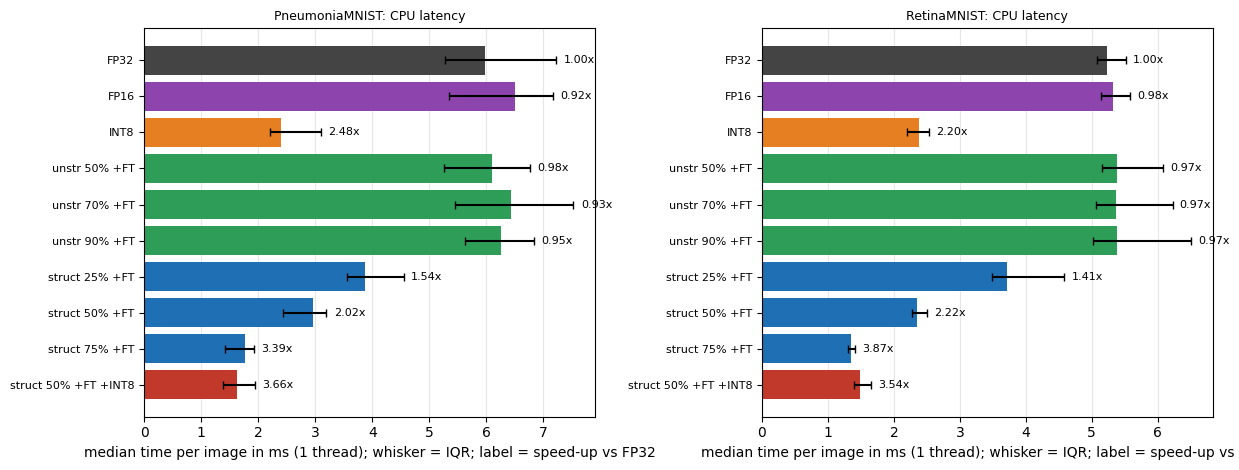

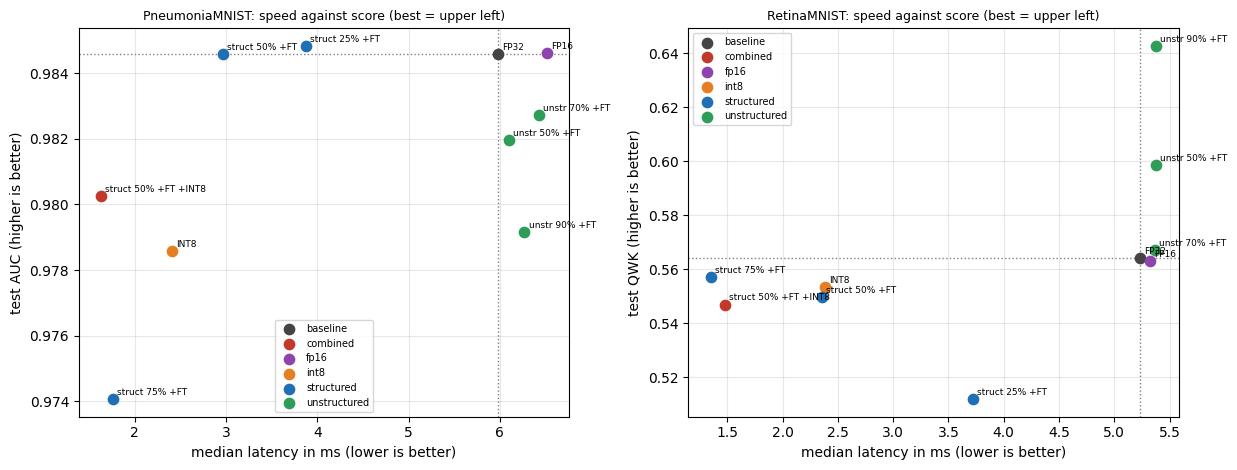

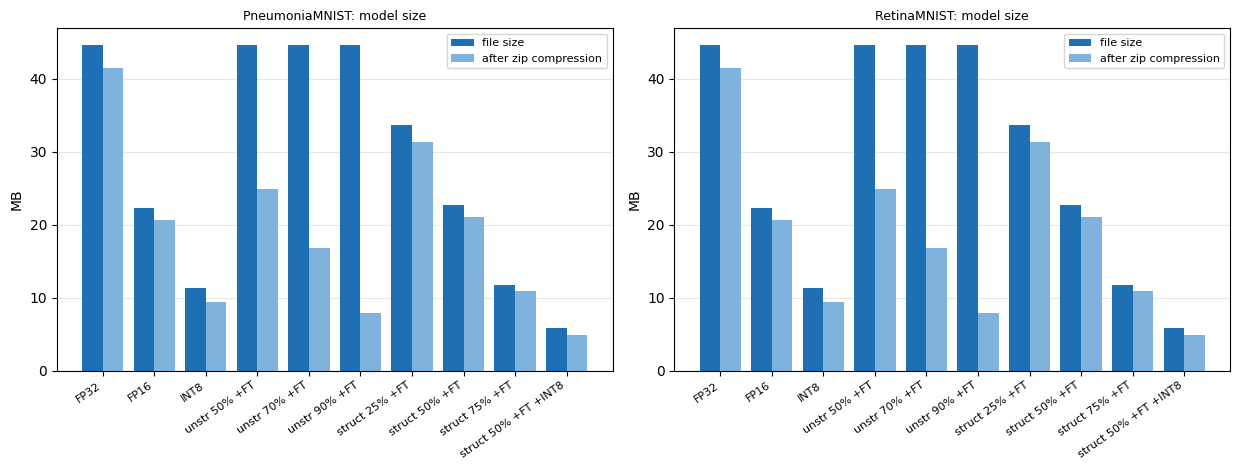

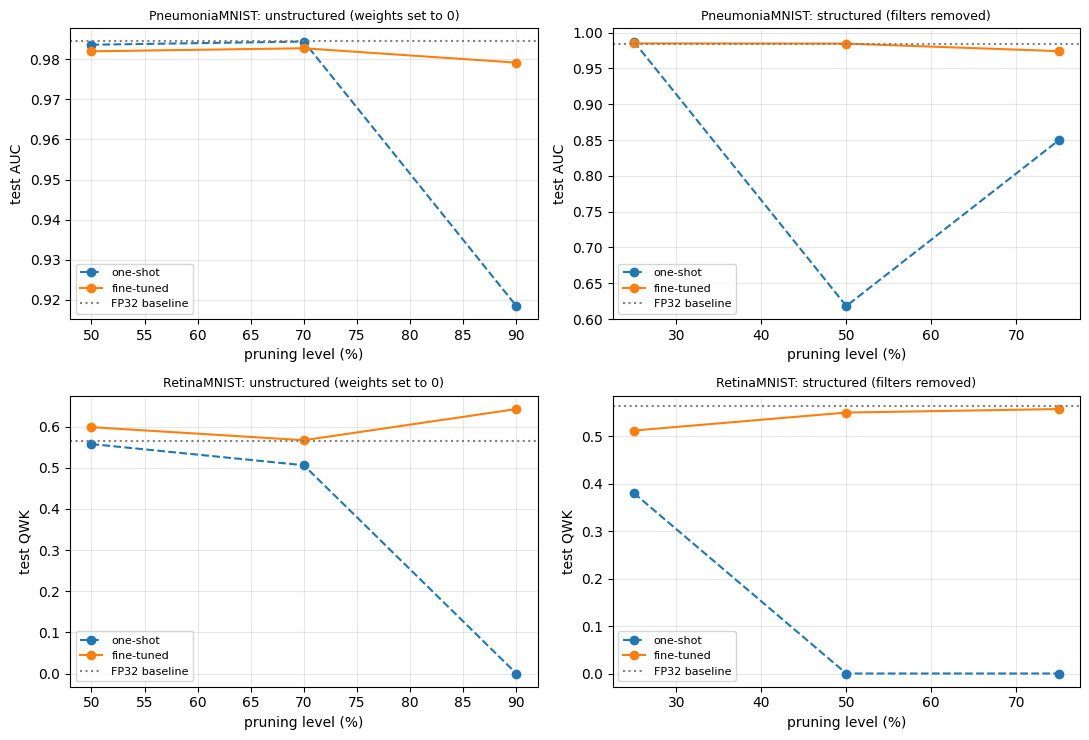

In [59]:
def plot_latency():
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
    for ax, flag in zip(axes, DATASETS):
        d = MASTER[flag]
        d = d[d["latency_ms"].notna()].reset_index(drop=True)
        ypos = np.arange(len(d))
        ax.barh(ypos, d["latency_ms"], xerr=[(d["latency_ms"] - d["p25"]).clip(lower=0), (d["p75"] - d["latency_ms"]).clip(lower=0)],
                color=[GROUP_COLORS[g] for g in d["group"]], capsize=3, zorder=2)
        for i, r_ in d.iterrows():
            ax.text(r_["latency_ms"] + (r_["p75"] - r_["latency_ms"]) + 0.02 * d["latency_ms"].max(), i, f"{r_['speedup']:.2f}x", va="center", fontsize=8)
        ax.set_yticks(ypos)
        ax.set_yticklabels(d["variant"], fontsize=8)
        ax.invert_yaxis()
        ax.set_xlabel(f"median time per image in ms ({N_THREADS} thread); whisker = IQR; label = speed-up vs FP32")
        ax.set_title(f"{NICE[flag]}: CPU latency", fontsize=9)
        ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", "latency.png"), dpi=150, bbox_inches="tight")
    plt.show()

def plot_tradeoff():
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
    for ax, flag in zip(axes, DATASETS):
        d = MASTER[flag]
        d = d[d["latency_ms"].notna()]
        pcol = PRIMARY_NAME[flag]
        for g, gd in d.groupby("group"):
            ax.scatter(gd["latency_ms"], gd[pcol], s=55, color=GROUP_COLORS[g], label=g, zorder=3)
        for _, r_ in d.iterrows():
            ax.annotate(r_["variant"], (r_["latency_ms"], r_[pcol]), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
        base = d[d.variant == "FP32"].iloc[0]
        ax.axhline(base[pcol], color="grey", ls=":", lw=1)
        ax.axvline(base["latency_ms"], color="grey", ls=":", lw=1)
        ax.set_xlabel("median latency in ms (lower is better)")
        ax.set_ylabel(f"test {pcol} (higher is better)")
        ax.set_title(f"{NICE[flag]}: speed against score (best = upper left)", fontsize=9)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", "tradeoff_latency_score.png"), dpi=150, bbox_inches="tight")
    plt.show()

def plot_sizes():
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
    for ax, flag in zip(axes, DATASETS):
        d = MASTER[flag]
        d = d[d["deployable"]].reset_index(drop=True)
        x = np.arange(len(d))
        ax.bar(x - 0.2, d["size_MB"], width=0.4, color="#1f6fb4", label="file size", zorder=2)
        ax.bar(x + 0.2, d["zip_MB"], width=0.4, color="#7fb2dd", label="after zip compression", zorder=2)
        ax.set_xticks(x)
        ax.set_xticklabels(d["variant"], rotation=35, ha="right", fontsize=8)
        ax.set_ylabel("MB")
        ax.set_title(f"{NICE[flag]}: model size", fontsize=9)
        ax.grid(axis="y", alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", "sizes.png"), dpi=150, bbox_inches="tight")
    plt.show()

def plot_pruning_curves():
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), squeeze=False)
    for r_, flag in enumerate(DATASETS):
        M = MASTER[flag]
        pcol = PRIMARY_NAME[flag]
        base = float(M.loc[M.variant == "FP32", pcol].iloc[0])
        for c_, (kind, title) in enumerate([("unstructured", "unstructured (weights set to 0)"), ("structured", "structured (filters removed)")]):
            ax = axes[r_][c_]
            for stage, style in [("one-shot", "o--"), ("fine-tuned", "o-")]:
                d = M[(M.group == kind) & (M.stage == stage)].copy()
                if d.empty:
                    continue
                d["level"] = d["variant"].str.extract(r"(\d+)%")[0].astype(float)
                d = d.sort_values("level")
                ax.plot(d["level"], d[pcol], style, label=stage)
            ax.axhline(base, color="grey", ls=":", label="FP32 baseline")
            ax.set_xlabel("pruning level (%)")
            ax.set_ylabel(f"test {pcol}")
            ax.set_title(f"{NICE[flag]}: {title}", fontsize=9)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", "pruning_curves.png"), dpi=150, bbox_inches="tight")
    plt.show()

plot_latency()
plot_tradeoff()
plot_sizes()
plot_pruning_curves()

In [60]:
def safe_name(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")

REC = {}
for flag in DATASETS:
    pcol = PRIMARY_NAME[flag]
    M = MASTER[flag].set_index("variant")
    base_val = M.loc["FP32", "val_" + pcol]
    cands = [v for v in VARIANTS[flag] if v["deployable"] and v["name"] in LAT[flag]
             and base_val - M.loc[v["name"], "val_" + pcol] <= TOLERANCE[flag]]
    fastest = min(cands, key=lambda v: np.median(LAT[flag][v["name"]]))
    smallest = min(cands, key=lambda v: v["size_mb"])
    REC[flag] = {"fastest": fastest["name"], "smallest": smallest["name"]}
    print("=" * 100)
    print(f"{NICE[flag]}: validation {pcol} of FP32 = {base_val:.3f}; accepted drop = {TOLERANCE[flag]}; {len(cands)} variants qualify")
    cols = ["size_MB", "zip_MB", "latency_ms", "speedup", "accuracy", pcol, "ECE", "NLL", "agree_with_FP32_%"]
    shown = []
    for kind, name in [("fastest", fastest["name"]), ("smallest", smallest["name"])]:
        row = MASTER[flag].set_index("variant").loc[[name], cols].copy()
        row.insert(0, "rule", kind)
        shown.append(row)
    display(pd.concat(shown).round(3))
    for name in {fastest["name"], smallest["name"]}:
        v = next(v for v in VARIANTS[flag] if v["name"] == name)
        shutil.copy(v["path"], os.path.join(OUT_DIR, "recommended_models", f"{flag}__{safe_name(name)}.onnx"))
print("\nThe recommended ONNX files were copied to:", os.path.join(OUT_DIR, "recommended_models"))

PneumoniaMNIST: validation AUC of FP32 = 0.998; accepted drop = 0.01; 10 variants qualify


,rule,size_MB,zip_MB,latency_ms,speedup,accuracy,AUC,ECE,NLL,agree_with_FP32_%
variant,,,,,,,,,,
struct 50% +FT +INT8,fastest,5.786,4.889,1.632,3.661,0.843,0.98,0.121,0.519,91.987
struct 50% +FT +INT8,smallest,5.786,4.889,1.632,3.661,0.843,0.98,0.121,0.519,91.987


RetinaMNIST: validation QWK of FP32 = 0.686; accepted drop = 0.03; 9 variants qualify


,rule,size_MB,zip_MB,latency_ms,speedup,accuracy,QWK,ECE,NLL,agree_with_FP32_%
variant,,,,,,,,,,
struct 50% +FT +INT8,fastest,5.787,4.888,1.479,3.537,0.538,0.547,0.152,1.237,64.75
struct 50% +FT +INT8,smallest,5.787,4.888,1.479,3.537,0.538,0.547,0.152,1.237,64.75



The recommended ONNX files were copied to: /content/drive/MyDrive/ML_Project3_Compression/full/recommended_models


## Step 14: Package everything for GitHub

This cell writes `results_tables.md` (all tables, ready to paste into your README) and creates `github_upload.zip` with the small files you should upload: tables, figures, the raw timing samples and the environment file. The ONNX models are **not** in the zip (they are large); the recommended ones stay in the `recommended_models` folder on your Drive. It also starts a download of the zip in Colab.

In [61]:
def df_to_markdown(d, index=True):
    d = d.reset_index() if index else d
    cols = list(d.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r_ in d.iterrows():
        cells = [f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v) for v in r_.values]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

parts = ["# Results tables (auto-generated)\n",
         f"Run: `{RUN_NAME}`. Test set. Reference models from Project 1: " + ", ".join(f"{NICE[f]} = `{REF[f]['config']}`" for f in DATASETS) + ".\n",
         f"CPU: {cpu_info()['cpu_model']} ({', '.join(cpu_info()['cpu_features']) or 'no special features found'}); {N_THREADS} thread(s); "
         f"batch size 1; ONNX Runtime {ort.__version__}.\n"]
for flag in DATASETS:
    parts.append(f"\n## {NICE[flag]}\n")
    parts.append("\n### Table 1: size, speed, accuracy, calibration\n")
    parts.append(df_to_markdown(MASTER_STR[flag]))
    parts.append("\n\n### Table 2: change vs FP32 with 95% bootstrap intervals over the test images\n")
    parts.append(df_to_markdown(DIFFS[flag], index=False))
    parts.append(f"\n\nRecommended by validation score (tolerance {TOLERANCE[flag]}): fastest = `{REC[flag]['fastest']}`, smallest = `{REC[flag]['smallest']}`.\n")
    if FAILED[flag]:
        parts.append("\nVariants that failed: " + "; ".join(f"{n} ({m[:80]})" for n, m in FAILED[flag]) + "\n")
with open(os.path.join(OUT_DIR, "results_tables.md"), "w", encoding="utf-8") as f:
    f.write("\n".join(parts))
print("Wrote results_tables.md")

export_dir = os.path.join(OUT_DIR, "github_upload")
os.makedirs(export_dir, exist_ok=True)
for fname in os.listdir(OUT_DIR):
    if fname.endswith((".csv", ".npz")) or fname in ("results_tables.md", "environment.json"):
        shutil.copy(os.path.join(OUT_DIR, fname), export_dir)
shutil.copytree(os.path.join(OUT_DIR, "figures"), os.path.join(export_dir, "figures"), dirs_exist_ok=True)
zip_path = shutil.make_archive(os.path.join(OUT_DIR, "github_upload"), "zip", export_dir)
print("Created:", zip_path)
if QUICK_TEST:
    print("\nNOTE: this was only the QUICK TEST. Do NOT upload these results. Set QUICK_TEST = False and run everything again.")
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("(Not in Colab: find the zip file at the path above.)")

Wrote results_tables.md
Created: /content/drive/MyDrive/ML_Project3_Compression/full/github_upload.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 15: Turn the results into a project

### 15a. How to read your results (write these sentences in your own words)
- **Size.** How many MB did FP16, INT8 and the structured models save? Did unstructured pruning change the file size? (It should not.) Did it change the zip size?
- **Speed.** Look at the speed-up column **with its interval**. Did FP16 help or hurt on this CPU? Did INT8 help (look at `cpu_features`)? Did unstructured pruning give a speed-up? Did structured pruning? If a speed-up interval includes 1.00, there is no clear speed change.
- **Accuracy and calibration.** In Table 2, which changes have an interval that excludes 0? How many predictions flipped (`changed`, `fixed`, `broken`)? Did ECE or NLL change? A compressed model can be slightly less (or more!) honest about its confidence.
- **One-shot against fine-tuned.** Look at the pruning curves: how much did fine-tuning recover?
- **The recommendation.** Which variant did the validation rule choose, and what are its *test* numbers? State the tolerance you used.

**Never write a number in your README that you did not get from your own run.**

### 15b. Limitations to state (honest limits are a strength)
- The speed was measured on a **cloud CPU with `N_THREADS` thread(s), not on a phone or a clinic laptop**, so only the ratios transfer, and only roughly. Other users share the machine, so timings are noisy (the intervals are slightly optimistic).
- **One trained model per dataset** (the Project 1 reference model) and small test sets: changes of a fraction of a percentage point are within the noise (see Table 2).
- Only **post-training** INT8 quantization with one calibration recipe; no quantization-aware training. FP16 was run on a CPU, where it usually has no native support.
- Unstructured pruning is simulated by zeros in a dense model; real gains would need sparse software or hardware. Structured pruning only touched the inner layer of each residual block.
- Memory use and energy were **not** measured. Low-resolution images. Not clinically validated.


2. Re-run everything with `QUICK_TEST = False`, then **File, Download, Download .ipynb**. Create a new public repository (for example `medical-model-compression`) and upload the notebook, the unzipped `github_upload.zip` and your README text. Do **not** upload the ONNX models. If you want to share one, the small INT8 one in `recommended_models` is fine (a few MB).



## Troubleshooting

| Problem | What to do |
|---|---|
| `FileNotFoundError ... reference_...pt` | Project 1's Step 9 did not run or saved somewhere else. Check `P1_DIR` in cell 1c and the `models` folder, or re-run Project 1 with `QUICK_TEST = False`. |
| `FAILED  FP16` or `FAILED  INT8` | That method is skipped; everything else continues. Fix the code. Run cell 1a again if the message says a module is missing. |
| The test score in Step 4 differs from Project 1 | Check that `IMG_SIZE` and the preprocessing are the same as in Project 1, and that `P1_DIR` is the `full_64px` folder (not a quick-test folder). |
| INT8 loses a lot of accuracy | Try `INT8_REDUCE_RANGE = True`, a larger `CALIB_N`, or `INT8_PER_CHANNEL = True` (the default). Report what you see. |
| FP16 is slower than FP32 | Not a bug: many CPUs have no native FP16 arithmetic. It is a result worth reporting. |
| `FAILED  evaluate FP16` (the file was created but cannot be opened) | This ONNX Runtime build cannot run FP16 models on your CPU. That is a finding: report it and continue. |
| The speed-up intervals are very wide | The machine was busy. Run the speed test again (cell 10) and use more rounds (`BENCH_ROUNDS`). |
| `NO GPU FOUND` | Fine-tuning then runs on the CPU and is slow. Use Runtime, Change runtime type, T4 GPU, then Run all. |
